In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# hard margin

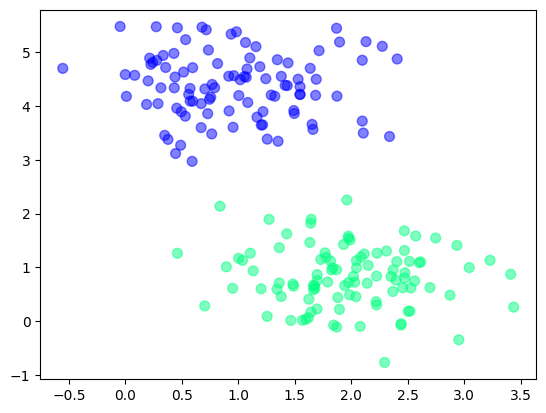

In [92]:
from sklearn.datasets import make_blobs
x,y = make_blobs(n_samples = 200 , centers = 2, random_state = 0 , cluster_std = 0.6)

plt.scatter(x[:,0],x[:,1],c=y,s=50,cmap='winter',alpha=0.5)

In [93]:
from sklearn.svm import SVC
model = SVC(kernel='linear' , C = 1)
model.fit(x,y)

SVC(C=1, kernel='linear')

In [94]:
print("weight vector : " , model.coef_[0])
print("bias : " , model.intercept_[0])
print("support vectors : ")
print(model.support_vectors_)

weight vector :  [ 0.29857719 -1.79135801]
bias :  4.448237766851025
support vectors : 
[[0.44359863 3.11530945]
 [0.59009904 2.96974544]
 [2.33812285 3.43116792]
 [0.83685684 2.13635938]
 [1.96066731 2.25169776]]


In [95]:
print("accuracy : " , model.score(x,y))

accuracy :  1.0


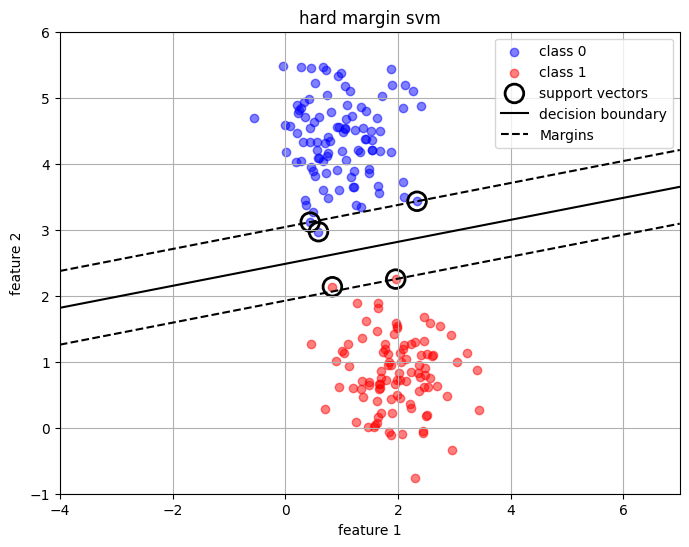

In [96]:
plt.figure(figsize=(8,6))

plt.scatter(
    x[y == 0,0],
    x[y == 0,1],
    color='blue',
    label = 'class 0',
    alpha = 0.5
)

plt.scatter(
    x[y == 1,0],
    x[y == 1,1],
    color = 'red',
    label = 'class 1',
    alpha = 0.5
)

plt.scatter(
    model.support_vectors_[:,0],
    model.support_vectors_[:,1],
    s=180,
    facecolors='none',
    edgecolors='black',
    linewidth=2,
    label="support vectors"
)

w = model.coef_[0]
b = model.intercept_[0]

x_min, x_max = -4, 7
x_values = np.linspace(x_min, x_max, 100)
decision_boundary = -(w[0]*x_values+b)/w[1]
margin_positive = -(w[0]*x_values+b-1)/w[1]
margin_negative = -(w[0]*x_values+b+1)/w[1]

plt.plot(
    x_values,
    decision_boundary,
    color='black',
    label="decision boundary"
)

plt.plot(
    x_values,
    margin_positive,
    "k--",
    label="Margins"
)

plt.plot(
    x_values,
    margin_negative,
    "k--"
)

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("hard margin svm")
plt.xlim(x_min,x_max)
plt.ylim(-1,6)

plt.legend()
plt.grid(True)
plt.show()

# soft margin

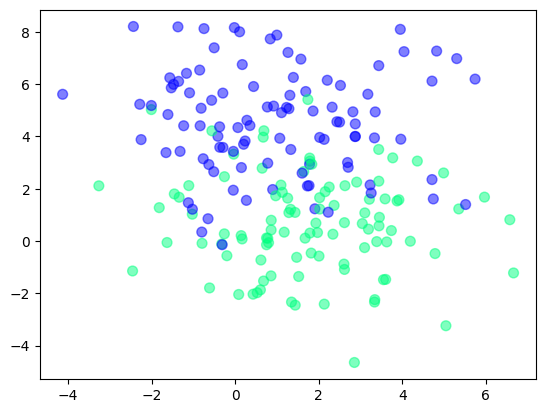

In [118]:
x, y = make_blobs(
    n_samples=200,
    centers=2,
    random_state=0,
    cluster_std=2
)

plt.scatter(x[:,0],x[:,1],c=y,s=50,cmap='winter',alpha=0.5)

In [122]:
model = SVC(kernel="linear", C=1)
model.fit(x,y)

SVC(C=1, kernel='linear')

In [123]:
print("weight vector : " , model.coef_[0])
print("bias : " , model.intercept_[0])
print("support vectors : ")
print(model.support_vectors_)

weight vector :  [ 0.12102952 -0.71939119]
bias :  1.6326112369994796
support vectors : 
[[-0.36865082  3.584681  ]
 [-0.79930142  0.34219439]
 [ 1.72912114  2.10498575]
 [-0.63054925  2.92468777]
 [-1.65554474  3.38061812]
 [-1.31866723  3.42814724]
 [ 2.12945171  3.88718982]
 [ 1.90759496  1.23129995]
 [ 0.89770444  1.96760033]
 [-0.0453402   1.94252296]
 [ 0.26828226  1.55388474]
 [ 3.33382922  3.94393766]
 [-0.04303428  3.42763872]
 [-0.65002249  0.85122212]
 [ 1.78095336  2.93416715]
 [-1.02416062  1.21424513]
 [ 3.25507145  1.83413569]
 [-0.29237411  3.578305  ]
 [ 1.33112236  3.50022546]
 [ 1.60240548  2.59559585]
 [ 2.87077401  3.99376714]
 [ 2.6899313   3.00173614]
 [ 1.7682835   2.11766431]
 [-0.51323957  2.65091025]
 [ 4.71138606  2.34923157]
 [-0.76532422  3.146088  ]
 [ 2.22673298  1.09967202]
 [ 2.0228234   3.96069467]
 [ 4.74257147  1.60826921]
 [-0.31096673 -0.14301898]
 [-1.12083585  1.46375145]
 [ 2.70514248  2.81945729]
 [ 3.22954192  2.14392431]
 [ 0.14903212  2.808

In [124]:
print("Accuracy:", model.score(x, y))

Accuracy: 0.83


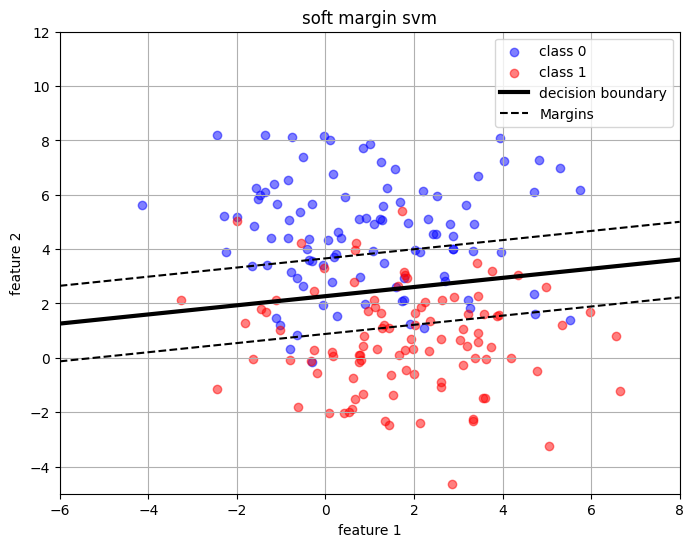

In [126]:
plt.figure(figsize=(8,6))

plt.scatter(
    x[y == 0,0],
    x[y == 0,1],
    color='blue',
    label = 'class 0',
    alpha = 0.5
)

plt.scatter(
    x[y == 1,0],
    x[y == 1,1],
    color = 'red',
    label = 'class 1',
    alpha = 0.5
)

w = model.coef_[0]
b = model.intercept_[0]

x_min, x_max = -6, 8
x_values = np.linspace(x_min, x_max, 100)
decision_boundary = -(w[0]*x_values+b)/w[1]
margin_positive = -(w[0]*x_values+b-1)/w[1]
margin_negative = -(w[0]*x_values+b+1)/w[1]

plt.plot(
    x_values,
    decision_boundary,
    color='black',
    label="decision boundary",
    linewidth = 3
)

plt.plot(
    x_values,
    margin_positive,
    "k--",
    label="Margins",
)

plt.plot(
    x_values,
    margin_negative,
    "k--"
)

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("soft margin svm") # Changed title from 'hard margin svm' to 'soft margin svm'
plt.xlim(x_min,x_max)
plt.ylim(-5,12)

plt.legend(loc = 'upper right')
plt.grid(True)
plt.show()